<h1 style="color: #00BFFF;">Amazon UK Product Insights</h1>

![legtsgo](https://i.giphy.com/media/v1.Y2lkPTc5MGI3NjExaWhwb2x2YjA1MjltMm1reTh3MDkzb2FsN21wenE3b2pjdnp4ems4dCZlcD12MV9pbnRlcm5hbF9naWZfYnlfaWQmY3Q9Zw/SvckSy7fFviqrq8ClF/giphy.gif)

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable insights.

**Dataset**: [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
provides information on product categories, brands, prices, ratings, and more from from Amazon UK.

In [260]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.options.display.float_format = "{:.2f}".format
np.set_printoptions(suppress=True)

In [4]:
df = pd.read_csv("amz_uk_price_prediction_dataset/amz_uk_price_prediction_dataset.csv")

In [5]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


In [ ]:
# Check for duplicates, NaNs and empty strings
print(f"Rows: {df.shape[0]}  |  Columns: {df.shape[1]}  |  Duplicated rows: {df.duplicated().sum()}")

quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulls": df.isna().sum(),
    "nulls_%": (df.isna().mean() * 100).round(1),
    "blanks": df.apply(lambda col: col.astype("string").str.strip().eq("").sum()),  # "", " ", "   "
    "n_unique": df.nunique(),
})

# Keep only the columns that actually have a problem, worst first
quality[(quality["nulls"] > 0) | (quality["blanks"] > 0)].sort_values("nulls_%", ascending=False)

Rows: 2443651  |  Columns: 9  |  Duplicated rows: 0


,dtype,nulls,nulls_%,blanks,n_unique


In [12]:
round(df.describe().T,2)

,count,mean,std,min,25%,50%,75%,max
uid,2443651.0,1370545.35,816056.17,1.0,658921.50,1349029.00,2060685.50,2828593.0
stars,2443651.0,2.15,2.19,0.0,0.00,0.00,4.40,5.0
reviews,2443651.0,480.63,5944.12,0.0,0.00,0.00,59.00,1356658.0
price,2443651.0,89.24,345.61,0.0,9.99,19.09,45.99,100000.0
boughtInLastMonth,2443651.0,25.90,240.48,0.0,0.00,0.00,0.00,50000.0


**Frequencies** 

Top 5 most listed product categories

In [37]:
Top_5=(df['category'].value_counts()).head(5).reset_index(name="count").merge((df['category'].value_counts(normalize=True).round(4)).head(5).reset_index(name="proportion"), on="category")
display(Top_5)

,category,count,proportion
0,Sports & Outdoors,836265,0.3422
1,Beauty,19312,0.0079
2,"Handmade Clothing, Shoes & Accessories",19229,0.0079
3,Bath & Body,19092,0.0078
4,Birthday Gifts,18978,0.0078


Distribution of products across different categories

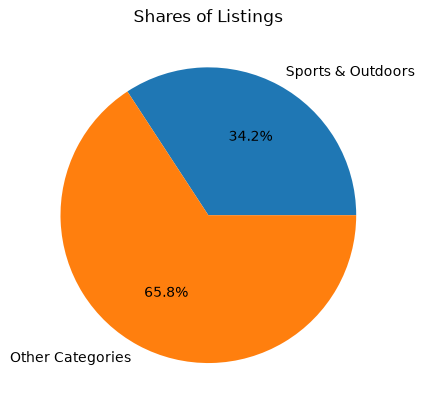

In [ ]:
sports = (df["category"] == "Sports & Outdoors").sum()
other = (df["category"] != "Sports & Outdoors").sum()
plt.pie([sports,other],labels=["Sports & Outdoors", "Other Categories"],autopct="%1.1f%%") 
plt.title("Shares of Listings")
plt.show()

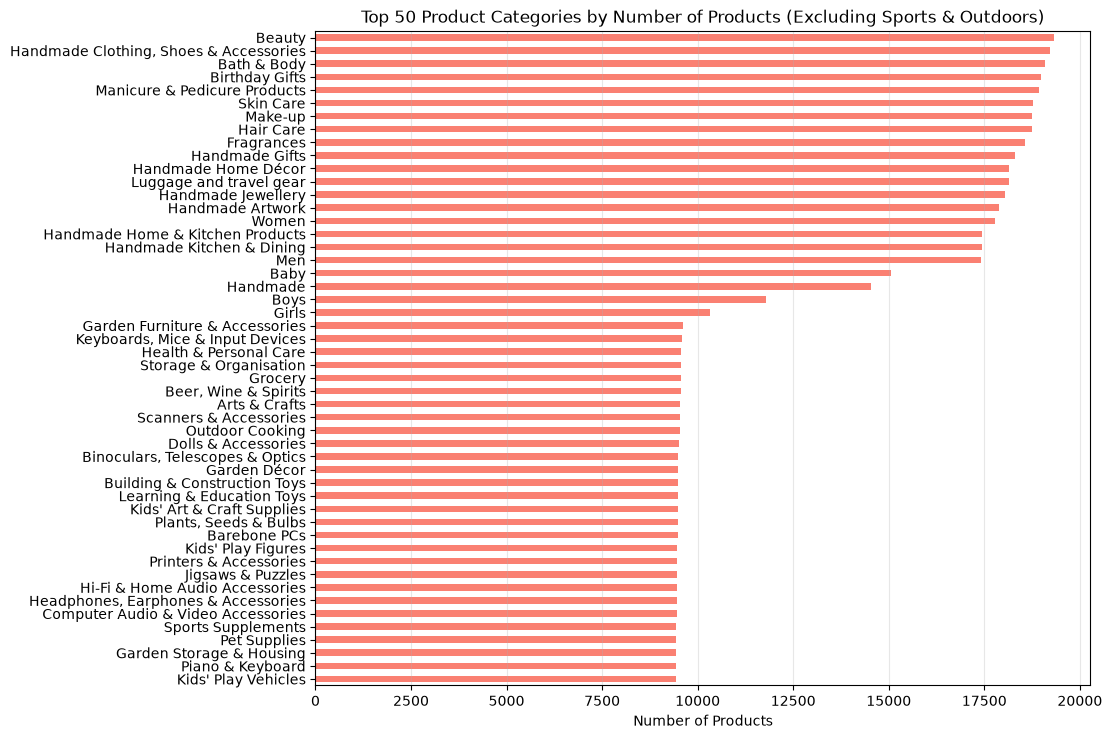

In [75]:
top_cat = df[df['category']!="Sports & Outdoors"]['category'].value_counts().head(50).sort_values()
ax = top_cat.plot(kind="barh",figsize=(10, 8.5),color="salmon", title="Top 50 Product Categories by Number of Products (Excluding Sports & Outdoors)")
ax.set_xlabel("Number of Products")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
plt.show()

**Product Pricing**

In [105]:
df_price = df[df["price"] > 0]
price_summary = pd.DataFrame({
    "Min": [round(df_price["price"].min(),10)],
    "Max": [df_price["price"].max()],
    "Mean": [df_price["price"].mean()],
    "Median": [df_price["price"].median()],
    "Mode": [df_price["price"].mode()[0]],
    "Variance": [df_price["price"].var()],
    "STD": [df_price["price"].std()],
    "Range": [df_price["price"].max() - df_price["price"].min()],
    "Interquartile range (IQR)": [df_price["price"].quantile(0.75) - df_price["price"].quantile(0.25)]
}).round(2)
price_summary

,Min,Max,Mean,Median,Mode,Variance,STD,Range,Interquartile range (IQR)
0,0.01,100000.0,89.24,19.09,9.99,119446.4,345.61,99999.99,36.0


Number of Products by Price Range (Considering wide price range, logarithmically spaced bins were used, so that all products could be grouped into appropriate price ranges)

In [258]:
bins = np.logspace(np.log10(df_price["price"].min()),np.log10(df_price["price"].max()),15)
labels = []
ranges = pd.cut(df_price["price"],bins=bins, include_lowest=True, precision=2)
price_ranges = ranges.value_counts(sort=False)
price_ranges

price
(0.0, 0.032]               703
(0.032, 0.1]                48
(0.1, 0.32]                358
(0.32, 1.0]               2410
(1.0, 3.16]              45575
(3.16, 10.0]            584305
(10.0, 31.62]           987543
(31.62, 100.0]          495435
(100.0, 316.23]         194706
(316.23, 1000.0]         93434
(1000.0, 3162.28]        33399
(3162.28, 10000.0]        5548
(10000.0, 31622.78]        165
(31622.78, 100000.0]         2
Name: count, dtype: int64

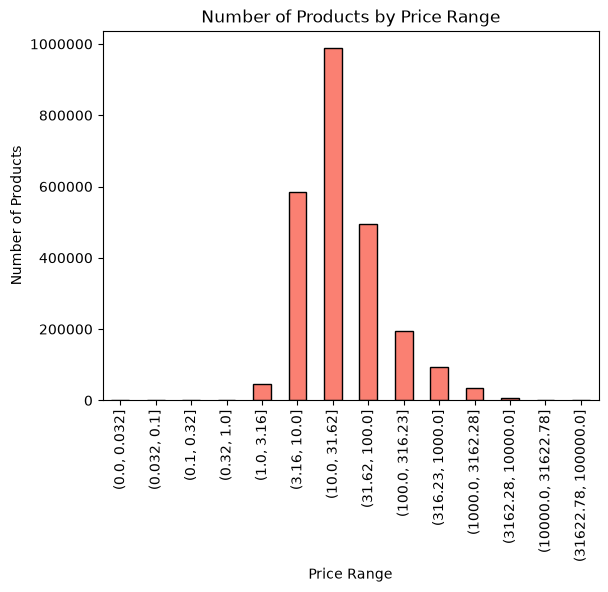

In [261]:
ax = price_ranges.plot(kind="bar",edgecolor="black",color="salmon")
ax.set_title("Number of Products by Price Range")
ax.set_ylabel("Number of Products")
ax.set_xlabel("Price Range")
plt.ticklabel_format(style="plain", axis="y")
plt.show()

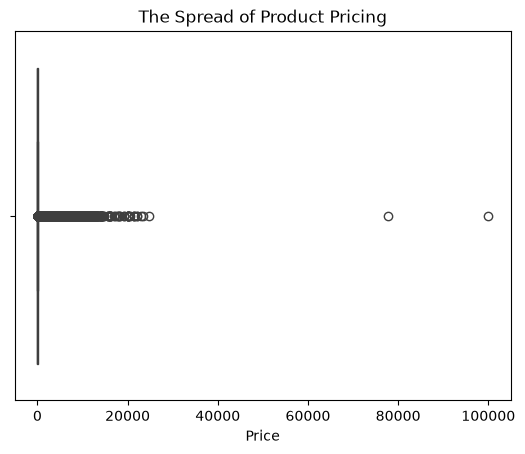

In [262]:
sns.boxplot(x=df_price["price"])
plt.title("The Spread of Product Pricing")
plt.xlabel("Price")
plt.show()

**Product Ratings**

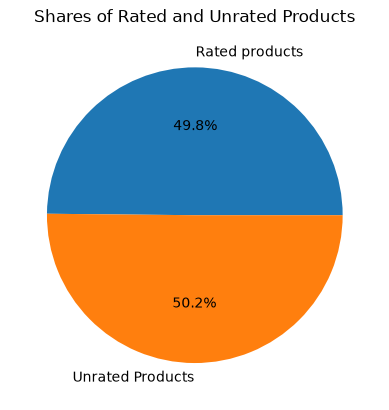

In [227]:
rated = (df["stars"] > 0).sum()
unrated = (df["stars"] == 0).sum()
plt.pie([rated,unrated],labels=["Rated products", "Unrated Products"],autopct="%1.1f%%") 
plt.title("Shares of Rated and Unrated Products")
plt.show()

In [254]:
stars = pd.to_numeric(df["stars"], errors="coerce")
df_rated = stars[stars > 0]
ranking = pd.DataFrame({
    "Min": [df_rated.min()],
    "Max": [df_rated.max()],
    "Mean": [df_rated.mean()],
    "Median": [df_rated.median()],
    "Mode": [df_rated.mode()[0]],
    "Variance": [df_rated.var()],
    "STD": [df_rated.std()],
    "Range": [df_rated.max() - df_rated.min()],
    "Interquartile range (IQR)": [df_rated.quantile(0.75) - df_rated.quantile(0.25)],
    "Skewness": [df_rated.skew()],
    "Kurtosis": [df_rated.kurt()]
})
ranking

,Min,Max,Mean,Median,Mode,Variance,STD,Range,Interquartile range (IQR),Skewness,Kurtosis
0,1.00,5.00,4.32,4.40,4.50,0.31,0.56,4.00,0.50,-2.38,9.78


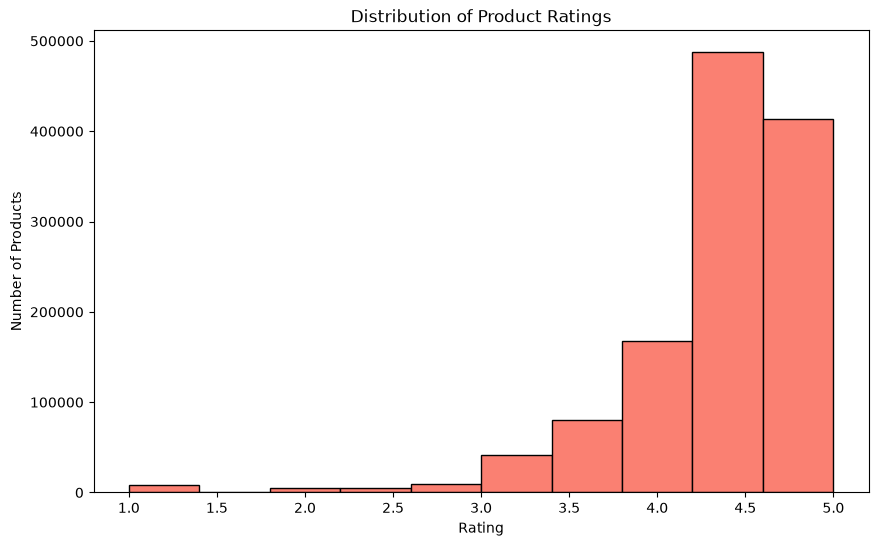

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(df_rated["stars"],edgecolor="black",color="salmon")
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()

**Product categories:** Sports & Outdoors is by far the most frequently listed category, representing about 34% of all listings. The remaining categories are much smaller individually, indicating a highly uneven distribution across categories.

**Product prices:** After excluding zero prices, the mean price is £89.24, while the median is £19.09 and the mode is £9.99. This large difference indicates a strongly right-skewed distribution. Most products fall within the £10–£31.62 price range, while a small number of very expensive products extend up to £100,000, producing a large standard deviation and high-price outliers.

**Product ratings:** Considering only rated products, the mean rating is 4.32, the median 4.40, and the mode 4.50, showing that ratings are generally high. The standard deviation is only 0.56 and the IQR is 0.50, indicating relatively low variation. The distribution is strongly negatively skewed (-2.38), meaning ratings are concentrated toward the upper end of the scale, and the high kurtosis (9.78) indicates that the distribution differs substantially from a normal distribution.